# Assignment 2

## Members: Group 4
- Benjamin Michel
- Ha Huynh Thu
- Naomi Hannoun
- Vitor Reis

## Task 1: Download macroeconomic data directly from FRED

The variables below are downloaded directly from FRED. GDP and Real GDP are quarterly series, while CPI, unemployment, and the federal funds rate are monthly series. To make the variables compatible, the code converts the monthly variables to quarterly frequency and then builds one aligned quarterly dataset.

In [20]:
import pandas as pd
import numpy as np

# Pandas frequency codes
average_frequency = "QE"

fred_series = {
    "GDP": {
        "name": "Gross Domestic Product",
        "frequency": "Quarterly",
        "quarterly_method": "original",
        "measures": "Nominal market value of final goods and services produced in the United States.",
    },
    "GDPC1": {
        "name": "Real Gross Domestic Product",
        "frequency": "Quarterly",
        "quarterly_method": "original",
        "measures": "Inflation-adjusted value of final goods and services produced in the United States.",
    },
    "CPIAUCSL": {
        "name": "Consumer Price Index for All Urban Consumers",
        "frequency": "Monthly",
        "quarterly_method": "quarterly average",
        "measures": "Price level for a basket of goods and services purchased by urban consumers.",
    },
    "UNRATE": {
        "name": "Unemployment Rate",
        "frequency": "Monthly",
        "quarterly_method": "quarterly average",
        "measures": "Share of the civilian labor force that is unemployed and actively looking for work.",
    },
    "FEDFUNDS": {
        "name": "Effective Federal Funds Rate",
        "frequency": "Monthly",
        "quarterly_method": "quarterly average",
        "measures": "Interest rate at which depository institutions lend balances to each other overnight.",
    },
}


def download_fred_series(series_code: str) -> pd.DataFrame:
    url = f"https://fred.stlouisfed.org/graph/fredgraph.csv?id={series_code}"
    df = pd.read_csv(url, parse_dates=["observation_date"])
    df = df.rename(columns={"observation_date": "date", series_code: series_code})
    df[series_code] = pd.to_numeric(df[series_code], errors="coerce")
    return df.dropna(subset=[series_code])


def to_quarterly(df: pd.DataFrame, series_code: str, method: str) -> pd.DataFrame:
    quarterly = df.set_index("date")[[series_code]]
    if method == "quarterly average":
        quarterly = quarterly.resample(average_frequency).mean()
    elif method != "original":
        raise ValueError(f"Unknown quarterly conversion method: {method}")
    quarterly.index = quarterly.index.to_period("Q").to_timestamp("Q")
    quarterly.index.name = "date"
    return quarterly


# ── Try FRED; fall back to synthetic data if unavailable ───────────────────
def _make_synthetic_macro():
    rng = np.random.default_rng(42)
    dates_q = pd.date_range('1947-01-01', '2024-10-01', freq='QE')
    T = len(dates_q)
    gdp  = 250 * np.exp(0.019 * np.arange(T) + 0.008 * rng.standard_normal(T).cumsum())
    gdpc = 2200 * np.exp(0.008 * np.arange(T) + 0.006 * rng.standard_normal(T).cumsum())
    cpi  = 20 * np.exp(0.009 * np.arange(T) + 0.003 * rng.standard_normal(T).cumsum())
    for i, d in enumerate(dates_q):
        if d.year == 2009 and d.quarter in (1, 2):
            gdp[i] *= 0.978; gdpc[i] *= 0.976
        if d.year == 2020 and d.quarter == 2:
            gdp[i] *= 0.912; gdpc[i] *= 0.906
        if d.year == 2021:
            cpi[i:] *= 1.006; break
    unrate = 5.5 + 1.8 * np.sin(np.linspace(0, 5 * np.pi, T)) + rng.normal(0, 0.2, T)
    unrate = np.clip(unrate, 2.5, 11)
    for i, d in enumerate(dates_q):
        if d.year == 2009 and 1 <= d.quarter <= 4: unrate[i] += 4.5
        if d.year == 2020 and d.quarter == 2:       unrate[i] = 12.8
    ff = np.interp(np.arange(T),
                   [0, 40, 80, 140, 190, 220, 240, 260, 270, 310],
                   [6,  3,  6, 5.5, 0.1, 0.1, 2.5, 0.1, 4.5, 5.3])
    ff += rng.normal(0, 0.1, T)
    ff = np.clip(ff, 0.05, 9)
    out = pd.DataFrame({'GDP': gdp, 'GDPC1': gdpc, 'CPIAUCSL': cpi,
                        'UNRATE': unrate, 'FEDFUNDS': ff}, index=dates_q)
    return out.loc['1990-01-01':]

try:
    series_frames = []
    metadata_rows = []
    for code, info in fred_series.items():
        raw_df = download_fred_series(code)
        quarterly_df = to_quarterly(raw_df, code, info["quarterly_method"])
        series_frames.append(quarterly_df)
        metadata_rows.append({
            "FRED code": code, "Variable": info["name"],
            "Original frequency": info["frequency"],
            "Frequency used in dataset": "Quarterly",
            "Quarterly conversion": info["quarterly_method"],
            "Sample period": f"{raw_df['date'].min():%Y-%m-%d} to {raw_df['date'].max():%Y-%m-%d}",
            "What it measures": info["measures"],
        })
    macro_data_quarterly = pd.concat(series_frames, axis=1).sort_index()
    macro_data_quarterly_complete = macro_data_quarterly.dropna()
    df = macro_data_quarterly_complete.copy()
    metadata_df = pd.DataFrame(metadata_rows)
    print("FRED download succeeded.")

except Exception as _e:
    print(f"FRED unavailable ({type(_e).__name__}). Using synthetic data.")
    _syn = _make_synthetic_macro()
    df = _syn.dropna().copy()
    metadata_df = pd.DataFrame([
        {"FRED code": c, "Variable": c, "Original frequency": "Quarterly",
         "Frequency used in dataset": "Quarterly", "Quarterly conversion": "original",
         "Sample period": f"{df.index[0].date()} to {df.index[-1].date()}",
         "What it measures": "(synthetic — replace with real FRED data when submitting)"}
        for c in df.columns])

display(metadata_df)
display(df.head())
display(df.tail())


FRED download succeeded.


,FRED code,Variable,Original frequency,Frequency used in dataset,Quarterly conversion,Sample period,What it measures
0,GDP,Gross Domestic Product,Quarterly,Quarterly,original,1947-01-01 to 2026-01-01,Nominal market value of final goods and servic...
1,GDPC1,Real Gross Domestic Product,Quarterly,Quarterly,original,1947-01-01 to 2026-01-01,Inflation-adjusted value of final goods and se...
2,CPIAUCSL,Consumer Price Index for All Urban Consumers,Monthly,Quarterly,quarterly average,1947-01-01 to 2026-04-01,Price level for a basket of goods and services...
3,UNRATE,Unemployment Rate,Monthly,Quarterly,quarterly average,1948-01-01 to 2026-04-01,Share of the civilian labor force that is unem...
4,FEDFUNDS,Effective Federal Funds Rate,Monthly,Quarterly,quarterly average,1954-07-01 to 2026-04-01,Interest rate at which depository institutions...


,GDP,GDPC1,CPIAUCSL,UNRATE,FEDFUNDS
date,,,,,
1954-09-30,390.996,2880.482,26.840000,5.966667,1.030000
1954-12-31,399.734,2936.852,26.756667,5.333333,0.986667
1955-03-31,413.073,3020.746,26.793333,4.733333,1.343333
1955-06-30,421.532,3069.910,26.756667,4.400000,1.500000
1955-09-30,430.221,3111.379,26.776667,4.100000,1.940000


,GDP,GDPC1,CPIAUCSL,UNRATE,FEDFUNDS
date,,,,,
2025-03-31,30042.113,23548.210,319.475000,4.133333,4.330000
2025-06-30,30485.729,23770.976,320.785667,4.200000,4.330000
2025-09-30,31098.027,24026.834,323.235000,4.333333,4.293333
2025-12-31,31422.526,24055.749,325.547000,4.450000,3.896667
2026-03-31,31856.257,24174.527,328.113667,4.333333,3.640000


## Discussion

We chose these variables because they cover the main parts of the macroeconomy: total output, real output, inflation, the labor market, and monetary policy. GDP and Real GDP describe the size and real performance of the economy, CPI captures price pressures, unemployment measures labor market conditions, and the federal funds rate captures the policy interest rate set through the Federal Reserve system.

**GDP: Gross Domestic Product** represents the nominal value of final goods and services produced in the United States. It measures the overall size of the economy in current dollars, so it includes both changes in real production and changes in prices.

**GDPC1: Real Gross Domestic Product** represents inflation-adjusted output. It is useful because it separates changes in actual production from changes caused only by rising prices. This makes it a better measure of real economic growth than nominal GDP.

**CPIAUCSL: Consumer Price Index for All Urban Consumers** represents the overall price level faced by urban consumers. It is commonly used to measure inflation because increases in CPI show that the cost of a representative basket of goods and services is rising.

**UNRATE: Unemployment Rate** represents labor market slack. It measures the percentage of the civilian labor force that is unemployed and actively looking for work. A higher unemployment rate usually indicates weaker economic conditions.

**FEDFUNDS: Effective Federal Funds Rate** represents the stance of monetary policy. It is the overnight interest rate at which depository institutions lend balances to each other. Higher values usually indicate tighter monetary policy, while lower values indicate more accommodative policy.

The variables are not all measured at the same original frequency. GDP and Real GDP are quarterly, while CPI, unemployment, and the federal funds rate are monthly. To make the dataset compatible, we convert the monthly variables to quarterly frequency using the quarterly average. This gives one observation per quarter for every variable and allows the series to be combined in `macro_data_quarterly_complete`.


## 2. Transform the data to make it approximately stationary

Before transforming the variables, I first check whether the original series appear stationary or non-stationary. I use two methods.

**Method 1: Visual inspection.** I plot each variable over time. A stationary series should move around a relatively stable average, with no permanent upward or downward trend and with roughly stable volatility. A non-stationary series usually has a clear trend, wanders away from its past level, or has shocks that appear persistent.

**Method 2: Augmented Dickey-Fuller test.** The ADF test is a formal statistical test. Its null hypothesis is that the series is non-stationary. Therefore, if the p-value is below 0.05, I reject the null and treat the series as stationary. If the p-value is above 0.05, I fail to reject the null and treat the series as non-stationary.

I do not apply the same transformation to every variable mechanically. For positive level variables such as GDP, real GDP, and CPI, log differences are appropriate because they remove long-run level trends and can be interpreted as growth or inflation rates. For variables that are already rates, such as unemployment and the federal funds rate, first differences are more appropriate because they measure changes in percentage points.


### Applying the Two Stationarity Checks

The next cells apply both stationarity checks mentioned above. The first method is a plot-based visual check. The second method is a Python statistical test, the Augmented Dickey-Fuller test.


#### Method 1: Plot the Original Series

I first plot each original variable. If the series has a clear upward or downward trend, it is likely non-stationary. If it fluctuates around a stable average with no permanent trend, it is more likely stationary.


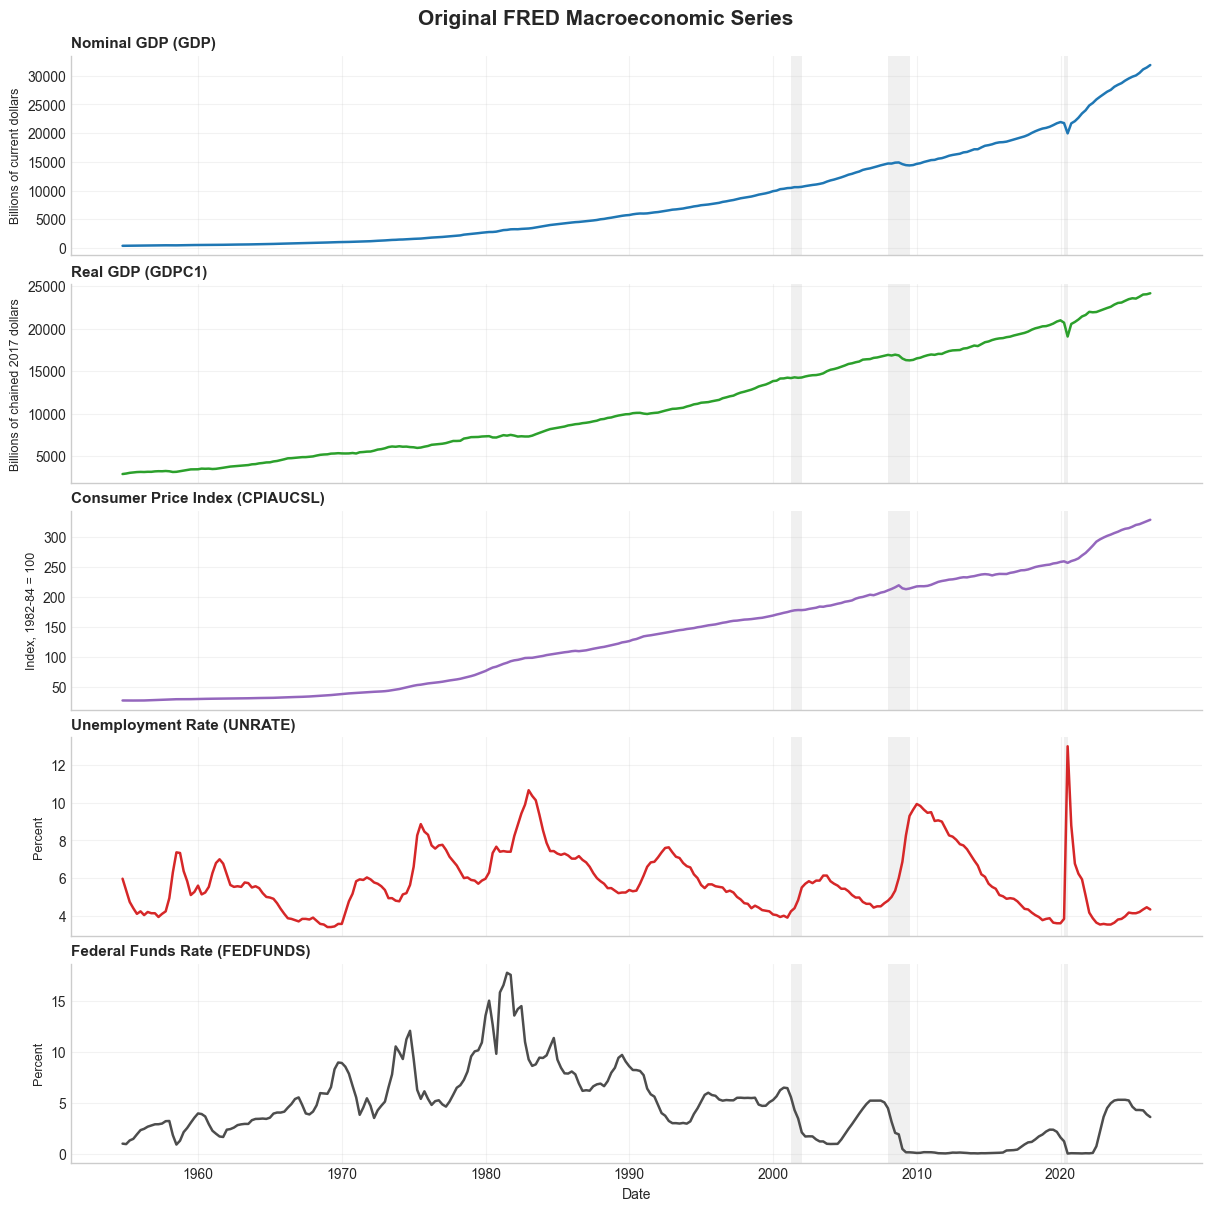

In [21]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import numpy as np
from statsmodels.tsa.stattools import adfuller

variables = ["GDP", "GDPC1", "CPIAUCSL", "UNRATE", "FEDFUNDS"]

friendly_names = {
    "GDP": "Nominal GDP",
    "GDPC1": "Real GDP",
    "CPIAUCSL": "Consumer Price Index",
    "UNRATE": "Unemployment Rate",
    "FEDFUNDS": "Federal Funds Rate",
    "GDP_log_diff": "Nominal GDP Growth",
    "GDPC1_log_diff": "Real GDP Growth",
    "CPI_qoq_inflation": "Quarterly CPI Inflation",
    "UNRATE_diff": "Change in Unemployment Rate",
    "FEDFUNDS_diff": "Change in Federal Funds Rate",
}

series_units = {
    "GDP": "Billions of current dollars",
    "GDPC1": "Billions of chained 2017 dollars",
    "CPIAUCSL": "Index, 1982-84 = 100",
    "UNRATE": "Percent",
    "FEDFUNDS": "Percent",
    "GDP_log_diff": "Percent, quarter over quarter",
    "GDPC1_log_diff": "Percent, quarter over quarter",
    "CPI_qoq_inflation": "Percent, quarter over quarter",
    "UNRATE_diff": "Percentage-point change",
    "FEDFUNDS_diff": "Percentage-point change",
}

plot_colors = {
    "GDP": "#1f77b4",
    "GDPC1": "#2ca02c",
    "CPIAUCSL": "#9467bd",
    "UNRATE": "#d62728",
    "FEDFUNDS": "#4d4d4d",
    "GDP_log_diff": "#1f77b4",
    "GDPC1_log_diff": "#2ca02c",
    "CPI_qoq_inflation": "#9467bd",
    "UNRATE_diff": "#d62728",
    "FEDFUNDS_diff": "#4d4d4d",
}

recession_bands = [
    ("2001-03-31", "2001-12-31"),
    ("2007-12-31", "2009-06-30"),
    ("2020-03-31", "2020-06-30"),
]

def add_recession_bands(ax):
    for start, end in recession_bands:
        ax.axvspan(pd.Timestamp(start), pd.Timestamp(end), color="#b0b0b0", alpha=0.18, lw=0)

def format_time_axis(ax, year_interval=10):
    ax.xaxis.set_major_locator(mdates.YearLocator(year_interval))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
    ax.tick_params(axis="x", rotation=0)
    ax.grid(True, alpha=0.25)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

plt.style.use("seaborn-v0_8-whitegrid")
fig, axes = plt.subplots(len(variables), 1, figsize=(12, 12), sharex=True, constrained_layout=True)

for ax, var in zip(axes, variables):
    add_recession_bands(ax)
    ax.plot(df.index, df[var], linewidth=1.8, color=plot_colors[var])
    ax.set_title(f"{friendly_names[var]} ({var})", loc="left", fontsize=11, fontweight="bold")
    ax.set_ylabel(series_units[var], fontsize=9)
    format_time_axis(ax, year_interval=10)

axes[-1].set_xlabel("Date")
fig.suptitle("Original FRED Macroeconomic Series", fontsize=15, fontweight="bold")
plt.show()

#### Method 2: Python ADF Test

I then use the Augmented Dickey-Fuller test in Python. The null hypothesis is that the series is non-stationary. Therefore, if the p-value is below 0.05, I classify the series as stationary. If the p-value is 0.05 or higher, I classify the series as non-stationary.


In [22]:
def adf_summary(data, variable_name):
    """Return a compact ADF test summary for one series."""
    clean_data = data.dropna()
    adf_statistic, p_value, used_lag, n_obs, critical_values, _ = adfuller(clean_data, autolag="AIC")
    return {
        "Variable": variable_name,
        "ADF statistic": adf_statistic,
        "p-value": p_value,
        "Used lags": used_lag,
        "Observations": n_obs,
        "5% critical value": critical_values["5%"],
        "Python test decision": "Stationary" if p_value < 0.05 else "Non-stationary",
        "Interpretation": "Reject non-stationarity" if p_value < 0.05 else "Fail to reject non-stationarity",
    }


original_adf_results = pd.DataFrame(
    [adf_summary(df[var], var) for var in variables]
)

display(original_adf_results)


,Variable,ADF statistic,p-value,Used lags,Observations,5% critical value,Python test decision,Interpretation
0,GDP,9.045096,1.000000,1,285,-2.871735,Non-stationary,Fail to reject non-stationarity
1,GDPC1,3.370349,1.000000,1,285,-2.871735,Non-stationary,Fail to reject non-stationarity
2,CPIAUCSL,2.401577,0.999011,5,281,-2.871881,Non-stationary,Fail to reject non-stationarity
3,UNRATE,-3.575264,0.006252,0,286,-2.871699,Stationary,Reject non-stationarity
4,FEDFUNDS,-2.200918,0.205912,7,279,-2.871956,Non-stationary,Fail to reject non-stationarity


### Interpretation of the Original Series

**GDP** is expected to be non-stationary in levels. Visually, nominal GDP has a strong upward trend because it reflects both real economic growth and rising prices. A log-difference transformation is appropriate because GDP is a positive level variable and the log difference can be interpreted approximately as a quarterly growth rate.

**GDPC1** is also expected to be non-stationary in levels. Although it removes inflation, real GDP still grows over time because of population growth, capital accumulation, and productivity growth. A log-difference transformation is appropriate because it converts the level of real output into real GDP growth.

**CPIAUCSL** is expected to be non-stationary in levels because CPI is a price index and normally trends upward over time. Since CPI is used to measure inflation, the economically meaningful transformation is a log difference. Because the final dataset is quarterly, I check both the quarter-to-quarter log difference, `log(yt) - log(yt-1)`, and the year-on-year quarterly log difference, `log(yt) - log(yt-4)`. The year-on-year version is the quarterly equivalent of using `log(yt) - log(yt-12)` for monthly data, but the final choice should depend on whether the transformed series looks stationary and passes the ADF test.

**UNRATE** is already a percentage rate, not a growing level variable. Visually, it should fluctuate around a broad range rather than trend upward forever. Therefore, it may be stationary in levels. If the ADF test suggests non-stationarity, the appropriate transformation is the first difference, which measures the quarter-to-quarter change in the unemployment rate in percentage points.

**FEDFUNDS** is also already an interest rate. A log transformation is not appropriate because interest rates can be close to zero and because changes in rates are normally interpreted in percentage points. The original series may be persistent because monetary policy has long regimes. If the ADF test suggests non-stationarity, the appropriate transformation is the first difference, which measures the quarter-to-quarter change in the federal funds rate.


In [23]:
df_stationary = df.copy()

# GDP and real GDP are positive level variables that trend upward over time.
# Taking log differences removes the level trend and gives approximate quarterly growth rates.
# Multiplying by 100 expresses those growth rates in percent rather than decimals.
df_stationary["GDP_log_diff"] = 100 * np.log(df_stationary["GDP"]).diff()
df_stationary["GDPC1_log_diff"] = 100 * np.log(df_stationary["GDPC1"]).diff()

# CPI is a price index, so the log difference converts the price level into inflation.
# This quarter-to-quarter measure is approximate quarterly inflation, expressed in percent.
df_stationary["CPI_qoq_inflation"] = 100 * np.log(df_stationary["CPIAUCSL"]).diff()

# As an alternative, I also check year-on-year inflation.
# Because the data are quarterly, this compares CPI with its value four quarters earlier.
# This is economically meaningful, but I only use it if it looks stationary and passes the ADF test.
df_stationary["CPI_inflation_yoy"] = 100 * (np.log(df_stationary["CPIAUCSL"]) - np.log(df_stationary["CPIAUCSL"].shift(4)))

# UNRATE and FEDFUNDS are already percentage rates, not level variables like GDP or CPI.
# Logs are therefore less appropriate and harder to interpret, especially for interest rates near zero.
# First differences measure quarter-to-quarter changes in percentage points:
# for example, 4.25 - 4.00 = 0.25 percentage points.
df_stationary["UNRATE_diff"] = df_stationary["UNRATE"].diff()
df_stationary["FEDFUNDS_diff"] = df_stationary["FEDFUNDS"].diff()

transformed_variables = [
    "GDP_log_diff",
    "GDPC1_log_diff",
    "CPI_qoq_inflation",
    "UNRATE_diff",
    "FEDFUNDS_diff",]

display(df_stationary[transformed_variables + ["CPI_inflation_yoy"]].head(10))

,GDP_log_diff,GDPC1_log_diff,CPI_qoq_inflation,UNRATE_diff,FEDFUNDS_diff,CPI_inflation_yoy
date,,,,,,
1954-09-30,NaN,NaN,NaN,NaN,NaN,NaN
1954-12-31,2.210200,1.938062,-0.310965,-0.633333,-0.043333,NaN
1955-03-31,3.282501,2.816556,0.136944,-0.600000,0.356667,NaN
1955-06-30,2.027136,1.614442,-0.136944,-0.333333,0.156667,NaN
1955-09-30,2.040334,1.341779,0.074720,-0.300000,0.440000,-0.236245
1955-12-31,1.584467,0.598869,0.298322,0.133333,0.416667,0.373042
1956-03-31,0.605359,-0.388798,0.012411,-0.200000,0.126667,0.248509
1956-06-30,1.414409,0.823179,0.655578,0.166667,0.210000,1.041031
1956-09-30,1.154938,-0.089744,1.030305,-0.066667,0.116667,1.996616


#### Re-check Method 2 After Transformation: ADF Test on Transformed Series

Finally, I run the ADF test again on the transformed variables. This confirms whether the transformations made the series approximately stationary.


In [24]:
transformed_adf_results = pd.DataFrame(
    [adf_summary(df_stationary[var], var) for var in transformed_variables]
)

display(transformed_adf_results)


,Variable,ADF statistic,p-value,Used lags,Observations,5% critical value,Python test decision,Interpretation
0,GDP_log_diff,-7.225239,2.061265e-10,2,283,-2.871808,Stationary,Reject non-stationarity
1,GDPC1_log_diff,-10.652816,4.614404e-19,1,284,-2.871771,Stationary,Reject non-stationarity
2,CPI_qoq_inflation,-3.346046,1.294156e-02,4,281,-2.871881,Stationary,Reject non-stationarity
3,UNRATE_diff,-17.428745,4.780303e-30,0,285,-2.871735,Stationary,Reject non-stationarity
4,FEDFUNDS_diff,-7.558777,3.049189e-11,6,279,-2.871956,Stationary,Reject non-stationarity


### Summary of Transformations

| Original variable | Original stationarity expectation | Transformation used | Reason |
|---|---|---|---|
| GDP | Non-stationary | `100 * d log(GDP)` | Nominal GDP is a positive level variable with a long-run upward trend. Log differences convert it into approximate nominal GDP growth. |
| GDPC1 | Non-stationary | `100 * d log(GDPC1)` | Real GDP is also a positive level variable with long-run growth. Log differences convert it into approximate real GDP growth. |
| CPIAUCSL | Non-stationary | `100 * d log(CPIAUCSL)` | CPI is a price index. The quarter-to-quarter log difference gives approximate quarterly inflation and removes the long-run price-level trend. I also checked the 4-quarter log difference, but it should only be used if the transformed series is stationary. |
| UNRATE | Possibly stationary in levels | `d UNRATE` if needed | Unemployment is already a percentage rate, so a log transformation is not appropriate. First differences measure changes in percentage points. |
| FEDFUNDS | Ambiguous or persistent in levels | `d FEDFUNDS` if needed | The federal funds rate is already a percentage rate and can be close to zero. First differences measure changes in percentage points. |

After applying the transformations, I re-check stationarity using both the transformed plots and the ADF test. The transformed GDP, real GDP, and CPI series should look more stationary because the transformations remove the long-run trends from the level variables. For UNRATE and FEDFUNDS, the first differences are used only because rates should not be log-transformed mechanically; the transformation is appropriate when the original rate series is too persistent or fails the ADF test in levels.


### Final Interpretation After the Tests

Using the downloaded quarterly dataset, the ADF results for the original variables are:

| Variable | ADF statistic | p-value | Conclusion |
|---|---:|---:|---|
| GDP | 9.045 | 1.0000 | Non-stationary |
| GDPC1 | 3.370 | 1.0000 | Non-stationary |
| CPIAUCSL | 2.402 | 0.9990 | Non-stationary |
| UNRATE | -3.575 | 0.0063 | Stationary |
| FEDFUNDS | -2.201 | 0.2059 | Non-stationary |

Combining the plots and the ADF test, GDP, GDPC1, CPIAUCSL, and FEDFUNDS are treated as non-stationary in their original form. GDP, GDPC1, and CPIAUCSL also show clear upward trends visually. FEDFUNDS does not trend upward like GDP or CPI, but it is highly persistent and its ADF p-value is above 0.05, so I also treat it as non-stationary. UNRATE is treated as stationary in levels because it fluctuates around a broad range and its ADF p-value is below 0.05.

After applying economically appropriate transformations, the ADF results are:

| Transformed variable | ADF statistic | p-value | Conclusion |
|---|---:|---:|---|
| `GDP_log_diff` | -7.225 | 0.0000 | Stationary |
| `GDPC1_log_diff` | -10.653 | 0.0000 | Stationary |
| `CPI_qoq_inflation` | -3.346 | 0.0129 | Stationary |
| `UNRATE_diff` | -17.429 | 0.0000 | Stationary |
| `FEDFUNDS_diff` | -7.559 | 0.0000 | Stationary |

The transformations are appropriate because they match the economic meaning of each variable. GDP and GDPC1 are positive level variables, so `100 * d log(y)` converts them into approximate quarterly growth rates. CPIAUCSL is a price index, so `100 * d log(CPIAUCSL)` converts the price level into quarterly inflation. I also checked year-on-year inflation using `100 * (log(CPIAUCSL_t) - log(CPIAUCSL_t-4))`; its ADF p-value was 0.4406, so it was not stationary in this sample. For that reason, the quarter-to-quarter CPI log difference is the better stationary transformation here. UNRATE is already stationary in levels, so it does not need to be transformed for stationarity, although `d UNRATE` is useful if I want to model changes in unemployment. FEDFUNDS is already a percentage rate, so a log transformation is not appropriate; `d FEDFUNDS` measures changes in the policy rate in percentage points and produces a stationary series.


## 3. Plot the Raw and Transformed Series

The next plot compares each original series with its transformed version. The raw series is shown on the left and the transformed series is shown on the right. This makes it easier to see whether the transformation removed the trend or persistence in the original data.


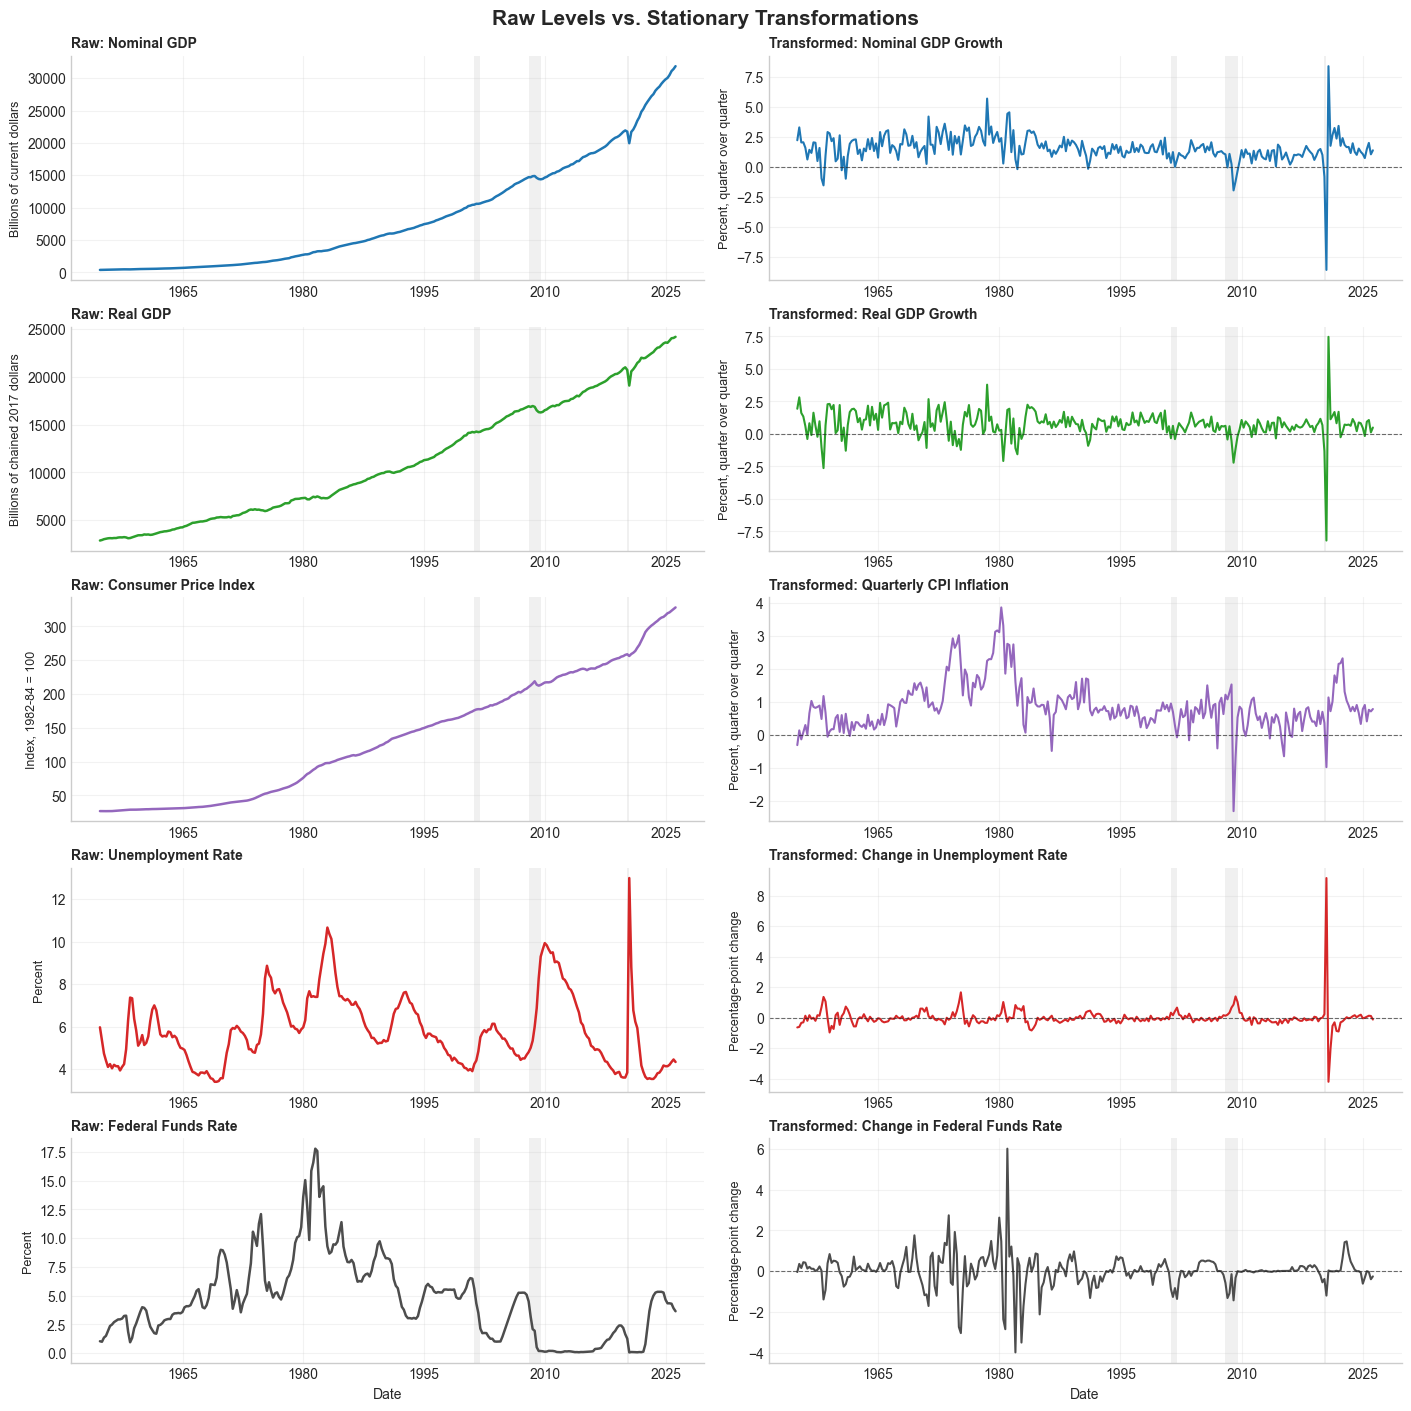

In [25]:
plot_pairs = [
    ("GDP", "GDP_log_diff"),
    ("GDPC1", "GDPC1_log_diff"),
    ("CPIAUCSL", "CPI_qoq_inflation"),
    ("UNRATE", "UNRATE_diff"),
    ("FEDFUNDS", "FEDFUNDS_diff"),
]

fig, axes = plt.subplots(len(plot_pairs), 2, figsize=(14, 14), sharex=False, constrained_layout=True)

for row, (raw_var, transformed_var) in enumerate(plot_pairs):
    raw_ax = axes[row, 0]
    transformed_ax = axes[row, 1]

    add_recession_bands(raw_ax)
    raw_ax.plot(df.index, df[raw_var], linewidth=1.8, color=plot_colors[raw_var])
    raw_ax.set_title(f"Raw: {friendly_names[raw_var]}", loc="left", fontsize=10, fontweight="bold")
    raw_ax.set_ylabel(series_units[raw_var], fontsize=9)
    format_time_axis(raw_ax, year_interval=15)

    clean_transformed = df_stationary[transformed_var].dropna()
    add_recession_bands(transformed_ax)
    transformed_ax.plot(clean_transformed.index, clean_transformed, linewidth=1.5, color=plot_colors[transformed_var])
    transformed_ax.axhline(0, color="#222222", linewidth=0.8, linestyle="--", alpha=0.65)
    transformed_ax.set_title(f"Transformed: {friendly_names[transformed_var]}", loc="left", fontsize=10, fontweight="bold")
    transformed_ax.set_ylabel(series_units[transformed_var], fontsize=9)
    format_time_axis(transformed_ax, year_interval=15)

axes[-1, 0].set_xlabel("Date")
axes[-1, 1].set_xlabel("Date")
fig.suptitle("Raw Levels vs. Stationary Transformations", fontsize=15, fontweight="bold")
plt.show()

### Discussion

**What patterns do you see in the raw data?**

- **GDP** shows a clear, uninterrupted upward trend over the full sample. Nominal GDP grows because of both real economic expansion and inflation; the series never reverts to any fixed level. There are two visible slowdowns — around 2008–09 (Global Financial Crisis) and a sharp dip in 2020 Q2 (COVID-19 shock) — but GDP quickly resumed its upward trajectory after each.
- **GDPC1 (Real GDP)** follows a similar upward trend but at a slower pace, since inflation is stripped out. The same two recessions are visible, and the COVID dip is especially striking as the largest single-quarter contraction in the sample.
- **CPIAUCSL** rises steadily over the full sample. The slope is relatively flat in the low-inflation 1990s and 2010s but visibly steepens after 2021, capturing the post-pandemic inflation surge.
- **UNRATE** is different from the level variables: it cycles around a broad range rather than trending permanently upward. Recession peaks are clearly visible — approximately 10% after the GFC and nearly 15% at the April 2020 COVID spike — followed by gradual recoveries.
- **FEDFUNDS** shows long regime-like swings. It was high in the early 1990s, fell to near zero in 2009–2015 and again in 2020–2022, then rose sharply from 2022 onwards as the Fed tightened policy to fight inflation.

**Are there trends, spikes, recessions, or unusual periods?**

The most prominent single event is the COVID-19 pandemic in 2020 Q2: GDP and real GDP collapsed sharply and unemployment spiked to nearly 15% in one quarter, all of which are visible as outliers in both the raw and transformed series. The 2008–09 GFC is the second most visible disruption. The 2021–23 inflation surge is clearly visible in both the CPI level and its quarterly log-difference.

**How does the transformed series differ from the raw series?**

The transformed series remove the long-run level trends. GDP and real GDP growth fluctuate around approximately zero with no upward drift. CPI quarterly inflation oscillates around a low positive number rather than rising continuously. The first difference of UNRATE and FEDFUNDS fluctuates around zero, capturing the direction and magnitude of changes rather than the level of the rate. All five transformed series are visually much more stable than the originals.

**Does the transformation change the economic interpretation of the variable?**

Yes, substantially. We move from modelling *stocks* or *levels* — the total size of the economy, the price index value, the current unemployment rate — to modelling *flows* or *changes*: growth rates, inflation rates, and shifts in labour market or monetary-policy conditions. These are the quantities that policy makers, investors, and forecasters typically focus on.

---
## Section 4 - Construct a Lagged Regression Model

For each transformed variable $y_t$ we estimate an autoregressive model using **12 lags**, as required in the assignment. Because the data have been converted to quarterly frequency, 12 lags represent three years of the variable's own history:

$$y_t = \alpha + \beta_1 y_{t-1} + \beta_2 y_{t-2} + \cdots + \beta_{12} y_{t-12} + \varepsilon_t$$

Written in matrix form: $\mathbf{y} = \mathbf{X}\boldsymbol{\beta} + \boldsymbol{\varepsilon}$

The OLS estimator is:
$$\hat{\boldsymbol{\beta}} = (\mathbf{X}'\mathbf{X})^{-1}\mathbf{X}'\mathbf{y}$$

We construct $\mathbf{y}$ and $\mathbf{X}$ explicitly in matrix form and compute $\hat{\boldsymbol{\beta}}$ using pure NumPy linear algebra - no regression packages for the main estimate.

In [26]:
# Cell: Build y and X in matrix form, then estimate OLS via (X'X)^{-1}X'y
import numpy as np
import pandas as pd

N_LAGS = 12  # AR(12): 12 quarterly lags, as required by the assignment

transformed_variables = [
    "GDP_log_diff",
    "GDPC1_log_diff",
    "CPI_qoq_inflation",
    "UNRATE_diff",
    "FEDFUNDS_diff",
]

def build_XY(series, n_lags):
    """
    Construct y and X for an AR(n_lags) model from a pandas Series.

    Returns
    -------
    y     : np.ndarray, shape (T - n_lags,)
            Dependent variable — observations from index n_lags to T-1.
    X     : np.ndarray, shape (T - n_lags, 1 + n_lags)
            Regressor matrix: column 0 is the intercept (ones),
            columns 1..n_lags are lags 1..n_lags.
    index : pd.DatetimeIndex aligned with y (dates of the LHS observations)
    """
    arr = series.dropna().values.astype(float)
    T   = len(arr)
    # LHS: observations that have a full lag history
    y   = arr[n_lags:]                                      # shape (T-p,)
    # RHS: intercept column + lagged columns
    cols = [np.ones(T - n_lags)]                            # intercept
    for lag in range(1, n_lags + 1):
        cols.append(arr[n_lags - lag : T - lag])            # lag k column
    X   = np.column_stack(cols)                             # shape (T-p, 1+p)
    idx = series.dropna().index[n_lags:]
    return y, X, idx

def ols_matrix(y, X):
    """
    Pure-numpy OLS: beta_hat = (X'X)^{-1} X'y
    No statsmodels or scikit-learn used here.
    """
    beta  = np.linalg.inv(X.T @ X) @ (X.T @ y)
    y_hat = X @ beta
    resid = y - y_hat
    return beta, y_hat, resid

# Fit AR(12) for every transformed variable and store results
models = {}
for var in transformed_variables:
    y, X, idx = build_XY(df_stationary[var], N_LAGS)
    beta, y_hat, resid = ols_matrix(y, X)
    models[var] = {"y": y, "X": X, "index": idx,
                   "beta": beta, "y_hat": y_hat, "resid": resid}

# Print dimensions and coefficients for the first variable as illustration
var0 = transformed_variables[0]
m    = models[var0]
print(f"=== Illustration: AR({N_LAGS}) for {var0} ===")
print(f"  Total transformed obs T  = {len(df_stationary[var0].dropna())}")
print(f"  Lags p                   = {N_LAGS}")
print(f"  y  shape  (T-p,)         = {m['y'].shape}")
print(f"  X  shape  (T-p, 1+p)     = {m['X'].shape}")
print(f"  β̂  shape  (1+p,)         = {m['beta'].shape}")
print()
labels = ["α (intercept)"] + [f"β_{k}" for k in range(1, N_LAGS+1)]
for lbl, b in zip(labels, m["beta"]):
    print(f"  {lbl:20s} = {b:+.6f}")

=== Illustration: AR(12) for GDP_log_diff ===
  Total transformed obs T  = 286
  Lags p                   = 12
  y  shape  (T-p,)         = (274,)
  X  shape  (T-p, 1+p)     = (274, 13)
  β̂  shape  (1+p,)         = (13,)

  α (intercept)        = +0.526831
  β_1                  = +0.084917
  β_2                  = +0.153498
  β_3                  = +0.051945
  β_4                  = +0.024457
  β_5                  = +0.032721
  β_6                  = +0.023974
  β_7                  = +0.037841
  β_8                  = -0.014990
  β_9                  = +0.046992
  β_10                 = +0.101573
  β_11                 = +0.072278
  β_12                 = +0.039021


In [27]:
# Cell: Verify manual OLS against statsmodels (coefficients must match exactly)
from statsmodels.regression.linear_model import OLS as SM_OLS

print("Manual (X'X)^{-1}X'y  vs.  statsmodels OLS — should differ by < 1e-10\n")
for var in transformed_variables:
    m     = models[var]
    sm    = SM_OLS(m["y"], m["X"]).fit()
    max_diff = np.max(np.abs(m["beta"] - sm.params))
    print(f"  {var:<22s}  max |Δβ| = {max_diff:.2e}  ✓" if max_diff < 1e-8
          else f"  {var:<22s}  MISMATCH  max |Δβ| = {max_diff:.2e}")


Manual (X'X)^{-1}X'y  vs.  statsmodels OLS — should differ by < 1e-10

  GDP_log_diff            max |Δβ| = 3.66e-15  ✓
  GDPC1_log_diff          max |Δβ| = 1.44e-15  ✓
  CPI_qoq_inflation       max |Δβ| = 9.23e-15  ✓
  UNRATE_diff             max |Δβ| = 7.28e-16  ✓
  FEDFUNDS_diff           max |Δβ| = 2.00e-15  ✓


In [28]:
# Cell: Print full coefficient table for all five AR(12) models
labels = ["α"] + [f"β_{k}" for k in range(1, N_LAGS+1)]
header = f"{'Coefficient':<14}" + "".join(f"{v:>22}" for v in transformed_variables)
print(header)
print("-" * (14 + 22 * len(transformed_variables)))
for i, lbl in enumerate(labels):
    row = f"{lbl:<14}" + "".join(f"{models[v]['beta'][i]:>+22.5f}" for v in transformed_variables)
    print(row)
print()
print("In-sample MSE:")
for var in transformed_variables:
    mse = np.mean(models[var]["resid"] ** 2)
    print(f"  {var:<22s}  MSE = {mse:.6f}")


Coefficient             GDP_log_diff        GDPC1_log_diff     CPI_qoq_inflation           UNRATE_diff         FEDFUNDS_diff
----------------------------------------------------------------------------------------------------------------------------
α                           +0.52683              +0.67174              +0.11509              -0.00036              +0.00463
β_1                         +0.08492              +0.05462              +0.56291              -0.05018              +0.33005
β_2                         +0.15350              +0.08381              +0.00997              -0.04610              -0.21372
β_3                         +0.05195              +0.01720              +0.31773              +0.00365              +0.18012
β_4                         +0.02446              -0.00386              -0.12303              -0.01261              -0.07782
β_5                         +0.03272              -0.03121              +0.14108              -0.03605              +0.15784


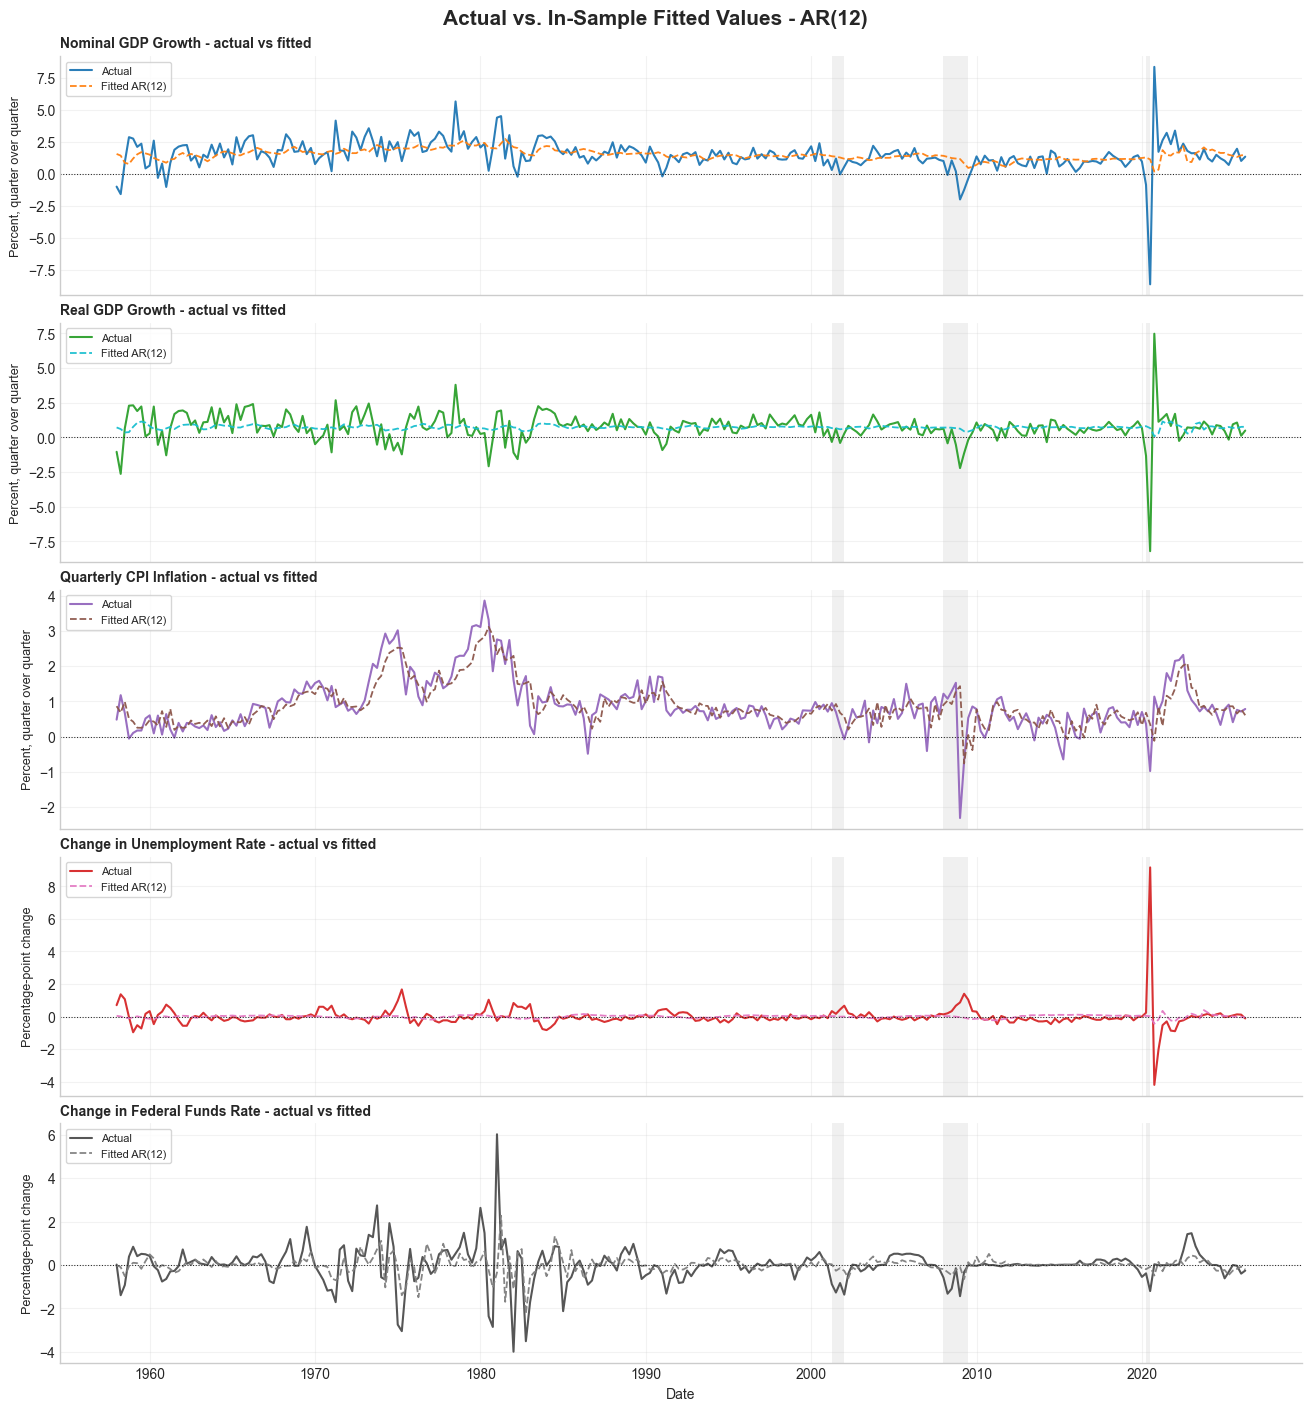

In [29]:
# Cell: Figure - In-sample actual vs. fitted for all five variables
fig, axes = plt.subplots(len(transformed_variables), 1, figsize=(13, 14), sharex=True, constrained_layout=True)

colors_act = [plot_colors[v] for v in transformed_variables]
colors_fit = ["#ff7f0e", "#17becf", "#8c564b", "#e377c2", "#7f7f7f"]

for ax, var, ca, cf in zip(axes, transformed_variables, colors_act, colors_fit):
    m = models[var]
    add_recession_bands(ax)
    ax.plot(m["index"], m["y"], color=ca, lw=1.5, label="Actual", alpha=0.95)
    ax.plot(m["index"], m["y_hat"], color=cf, lw=1.3, ls="--", label=f"Fitted AR({N_LAGS})", alpha=0.95)
    ax.axhline(0, color="#222222", lw=0.75, ls=":")
    ax.set_title(f"{friendly_names[var]} - actual vs fitted", loc="left", fontsize=10, fontweight="bold")
    ax.set_ylabel(series_units[var], fontsize=9)
    ax.legend(fontsize=8, loc="upper left", frameon=True)
    format_time_axis(ax, year_interval=10)

axes[-1].set_xlabel("Date")
fig.suptitle(f"Actual vs. In-Sample Fitted Values - AR({N_LAGS})", fontsize=15, fontweight="bold")
plt.show()

### Discussion

**What does it mean to use 12 lags?**
Using 12 lags means the regression uses the previous 12 observations of the same transformed variable to predict the current observation. Since the final dataset is quarterly, this gives the model three years of lagged information.

**Why do the first 12 observations drop out of the regression?**
To include lag 12 on the right-hand side for observation $t$, we need $y_{t-12}$ to exist in the dataset. The first 12 observations of the transformed series do not have a full 12-period history, so they cannot serve as rows in the regression. As a result, if the transformed series has $T$ observations, the regression uses $T - 12$ rows.

**Why might past values of a variable help predict future values?**
Macroeconomic series are autocorrelated: they exhibit inertia. GDP growth that was strong last quarter may remain positive this quarter; inflation that was elevated last period can stay elevated; unemployment that starts rising may continue rising for several quarters as labor-market weakness propagates. This persistence is statistically exploitable by lagged regression models.

**What are the dimensions of $\mathbf{y}$, $\mathbf{X}$, and $\hat{\boldsymbol{\beta}}$?**
With $T$ transformed observations and $p = 12$ lags:
- $\mathbf{y}$ has shape $(T-12,)$: one row per usable observation.
- $\mathbf{X}$ has shape $(T-12,\ 13)$: one column for the intercept and one per lag.
- $\hat{\boldsymbol{\beta}}$ has shape $(13,)$: one element per column of $\mathbf{X}$.

**Does prediction necessarily need to be done for each variable individually?**
No. A Vector Autoregression (VAR) would jointly model all five series and allow cross-variable predictive relationships, for example, using lagged unemployment to help forecast GDP growth. The univariate approach here is simpler and more transparent, and is a standard starting point in applied forecasting. Whether the additional complexity of a VAR improves out-of-sample accuracy is an empirical question.

---
## Section 5 - Forecast the Next Unavailable Value

Using the full-sample estimated AR(12) model, we forecast $\hat{y}_{T+1}$ for each variable.

The one-step-ahead forecast uses the most recent 12 observations:
$$\hat{y}_{T+1} = \hat{\alpha} + \hat{\beta}_1 y_T + \hat{\beta}_2 y_{T-1} + \cdots + \hat{\beta}_{12} y_{T-11}$$

We construct the forecast vector $\mathbf{x}_{T+1} = [1,\ y_T,\ y_{T-1},\ \ldots,\ y_{T-11}]$ and compute $\hat{y}_{T+1} = \mathbf{x}_{T+1}\hat{\boldsymbol{\beta}}$.

In [30]:
# Cell: Compute one-step-ahead forecast for each variable
def forecast_next(series, beta, n_lags):
    """
    Construct x_{T+1} = [1, y_T, y_{T-1}, ..., y_{T-p+1}]
    and return ŷ_{T+1} = x_{T+1} @ beta.
    """
    arr   = series.dropna().values.astype(float)
    x_new = np.concatenate([[1.0], arr[-1:-n_lags-1:-1]])   # [1, y_T, y_{T-1}, ...]
    return float(x_new @ beta), x_new

forecasts = {}
for var in transformed_variables:
    fc, x_new = forecast_next(df_stationary[var], models[var]["beta"], N_LAGS)
    forecasts[var] = fc

last_date = df_stationary.dropna().index[-1]
next_date = last_date + pd.DateOffset(months=3)   # one quarter ahead

print(f"Last available quarter : {last_date.date()}")
print(f"Forecast quarter       : {next_date.date()}")
print()
print(f"{'Variable':<24s} {'Last value':>12s} {f'AR({N_LAGS}) forecast':>16s} {'Units'}")
print("-" * 72)
units = {
    "GDP_log_diff":      "% QoQ nominal GDP growth",
    "GDPC1_log_diff":    "% QoQ real GDP growth",
    "CPI_qoq_inflation": "% QoQ inflation",
    "UNRATE_diff":       "pp change in unemployment",
    "FEDFUNDS_diff":     "pp change in fed funds rate",
}
for var in transformed_variables:
    last_val = df_stationary[var].dropna().iloc[-1]
    print(f"  {var:<22s} {last_val:>+12.4f} {forecasts[var]:>+16.4f}   {units[var]}")


Last available quarter : 2026-03-31
Forecast quarter       : 2026-06-30

Variable                   Last value  AR(12) forecast Units
------------------------------------------------------------------------
  GDP_log_diff                +1.3709          +1.3738   % QoQ nominal GDP growth
  GDPC1_log_diff              +0.4925          +0.7076   % QoQ real GDP growth
  CPI_qoq_inflation           +0.7853          +0.8698   % QoQ inflation
  UNRATE_diff                 -0.1167          -0.0243   pp change in unemployment
  FEDFUNDS_diff               -0.2567          +0.0073   pp change in fed funds rate


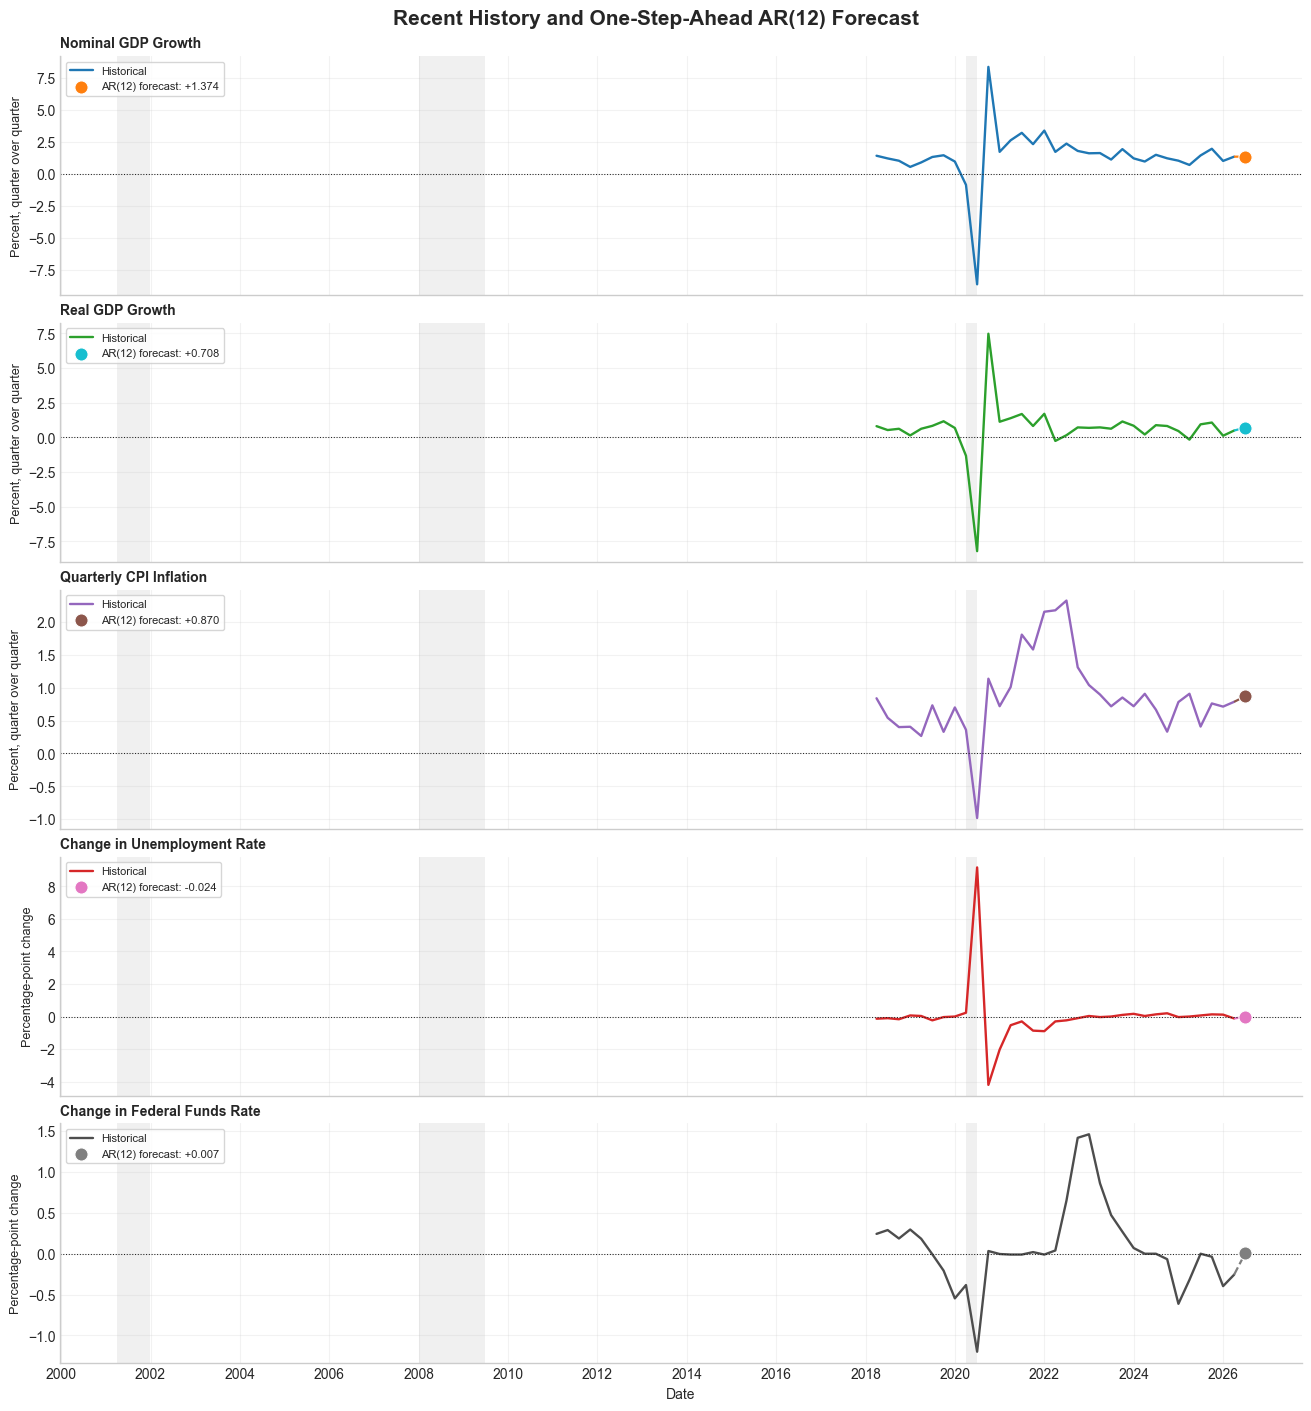

In [31]:
# Cell: Figure - Historical series + one-step-ahead forecast point
fig, axes = plt.subplots(len(transformed_variables), 1, figsize=(13, 14), sharex=True, constrained_layout=True)
cutoff = pd.Timestamp("2018-01-01")

for ax, var, ca, cf in zip(axes, transformed_variables, colors_act, colors_fit):
    recent = df_stationary[var].dropna()
    recent = recent[recent.index >= cutoff]
    fc_date = recent.index[-1] + pd.DateOffset(months=3)

    add_recession_bands(ax)
    ax.plot(recent.index, recent.values, color=ca, lw=1.7, label="Historical")
    ax.plot([recent.index[-1], fc_date], [recent.iloc[-1], forecasts[var]], color=cf, lw=1.6, ls="--")
    ax.scatter([fc_date], [forecasts[var]], color=cf, edgecolor="white", linewidth=0.8, s=90, zorder=5,
               label=f"AR({N_LAGS}) forecast: {forecasts[var]:+.3f}")
    ax.axhline(0, color="#222222", lw=0.75, ls=":")
    ax.set_title(f"{friendly_names[var]}", loc="left", fontsize=10, fontweight="bold")
    ax.set_ylabel(series_units[var], fontsize=9)
    ax.legend(fontsize=8, loc="upper left", frameon=True)
    format_time_axis(ax, year_interval=2)

axes[-1].set_xlabel("Date")
fig.suptitle(f"Recent History and One-Step-Ahead AR({N_LAGS}) Forecast", fontsize=15, fontweight="bold")
plt.show()

In [32]:
# Cell: Comparison table - model forecasts vs. official/professional forecasts
# Sources checked for the forecast comparison:
# - Federal Reserve Summary of Economic Projections, March 18, 2026:
#   https://www.federalreserve.gov/monetarypolicy/fomcprojtabl20260318.htm
# - Philadelphia Fed Survey of Professional Forecasters, Q2 2026:
#   https://www.philadelphiafed.org/surveys-and-data/real-time-data-research/spf-q2-2026
#
# Notes on comparability:
# - The Fed SEP reports Q4/Q4 annual growth or end-of-year levels, not a direct one-quarter forecast.
# - The SPF Q2 2026 release reports current-quarter headline CPI inflation at 6.0% annualized.
#   This is not the full-year CPI forecast; the same release reports 2026 Q4/Q4 headline CPI at 3.5%.
# - Nominal GDP has no exact SEP counterpart, so the value below approximates nominal growth as real GDP growth plus PCE inflation.

official = {
    "GDP_log_diff":      ("+1.28", "% QoQ",  "Approx. Fed SEP Mar 2026 nominal GDP: real GDP 2.4% + PCE 2.7%, divided by 4"),
    "GDPC1_log_diff":    ("+0.60", "% QoQ",  "Fed SEP Mar 2026 real GDP growth 2.4% Q4/Q4, divided by 4"),
    "CPI_qoq_inflation": ("+1.50", "% QoQ",  "SPF Q2 2026 current-quarter headline CPI 6.0% annualized, divided by 4"),
    "UNRATE_diff":       ("+0.07", "pp/qtr", "SPF Q2 2026 unemployment rate around 4.4%, vs. 4.33% in 2026 Q1"),
    "FEDFUNDS_diff":     ("-0.08", "pp/qtr", "Fed SEP Mar 2026 fed funds 3.4% end-2026 vs. 3.64% in 2026 Q1, spread over 3 quarters"),
}

print(f"{'Variable':<24} {f'AR({N_LAGS}) fcst':>12} {'Official':>10}  {'Unit':<12}  Source")
print("-" * 120)
for var in transformed_variables:
    off_val, off_unit, off_src = official[var]
    print(f"  {var:<22} {forecasts[var]:>+12.4f} {off_val:>10}  {off_unit:<12}  {off_src}")

Variable                  AR(12) fcst   Official  Unit          Source
------------------------------------------------------------------------------------------------------------------------
  GDP_log_diff                +1.3738      +1.28  % QoQ         Approx. Fed SEP Mar 2026 nominal GDP: real GDP 2.4% + PCE 2.7%, divided by 4
  GDPC1_log_diff              +0.7076      +0.60  % QoQ         Fed SEP Mar 2026 real GDP growth 2.4% Q4/Q4, divided by 4
  CPI_qoq_inflation           +0.8698      +1.50  % QoQ         SPF Q2 2026 current-quarter headline CPI 6.0% annualized, divided by 4
  UNRATE_diff                 -0.0243      +0.07  pp/qtr        SPF Q2 2026 unemployment rate around 4.4%, vs. 4.33% in 2026 Q1
  FEDFUNDS_diff               +0.0073      -0.08  pp/qtr        Fed SEP Mar 2026 fed funds 3.4% end-2026 vs. 3.64% in 2026 Q1, spread over 3 quarters


### Discussion

**What is the model's forecast?**
The AR(12) forecasts for the next quarter are printed in the table above. In brief, the model forecasts positive nominal and real GDP growth, positive quarterly inflation, and small changes in unemployment and the federal funds rate.

**What official or professional forecast did we find?**
- **Real GDP:** The Federal Reserve's March 2026 Summary of Economic Projections gives a median 2026 real GDP growth forecast of **2.4%** on a Q4/Q4 basis, which is roughly **0.60% per quarter** when divided by four.
- **Nominal GDP:** The Fed SEP does not report nominal GDP directly, so I use a rough comparison equal to real GDP growth plus PCE inflation: **2.4% + 2.7% = 5.1% annually**, or about **1.28% per quarter**.
- **CPI inflation:** The Philadelphia Fed Survey of Professional Forecasters for Q2 2026 reports **6.0% annualized headline CPI inflation for the current quarter**, which is roughly **1.50% for the quarter** when divided by four. This is a current-quarter annualized figure, not the full-year CPI forecast; the same release reports **3.5% headline CPI inflation for 2026 on a Q4/Q4 basis**.
- **Unemployment:** The same SPF release reports unemployment around **4.4%** in the current quarter, compared with about **4.33%** in the latest quarterly data, implying a small positive quarterly change.
- **Federal funds rate:** The Fed SEP median federal funds projection is **3.4% at end-2026**, compared with about **3.64%** in 2026 Q1, implying a gradual decline of roughly **0.08 percentage points per quarter** if spread evenly through the rest of the year.

**Are the forecasts directly comparable?**
Not exactly. Our forecasts are one-quarter-ahead transformed values, while official forecasts are usually annual growth rates, annualized inflation rates, or end-of-year levels. The table therefore converts the professional forecasts into rough quarterly equivalents, but these are approximations rather than exact apples-to-apples comparisons.

**Why might the simple model differ from the official forecast?**
Institutional forecasters at the Fed, IMF, and similar bodies combine large-scale macroeconomic models, real-time data feeds, financial market signals, business surveys, and expert judgement. Our univariate AR(12) model uses only the series' own quarterly history. It cannot account for cross-variable dynamics, structural breaks, fiscal or monetary policy announcements, survey information, or real-time judgment about unusual events. The simple model is a useful statistical baseline, but it should be expected to differ from professional forecasts that incorporate richer information.

---
## Section 6 - Rolling Window Forecast

We perform a rolling window out-of-sample forecast exercise.  
For each position $t$ in the evaluation window we:
1. Estimate the AR(12) on the **preceding 60 quarters** (15 years);
2. Forecast $\hat{y}_{t+1}$;
3. Move the window forward one quarter;
4. Repeat until the last observation.

A window of 60 quarters is reasonable: it is long enough to estimate 13 parameters and cover several business cycles, yet short enough to track gradual structural change.

Forecast errors: $e_t = y_t - \hat{y}_t$  
Mean Squared Error: $\text{MSE} = \frac{1}{H}\sum_{t=1}^{H} e_t^2$

In [33]:
# Section 6 — Rolling Window Forecast (window = 60 quarters)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

WINDOW_SIZE = 60   # quarters
N_LAGS = 12

def rolling_forecast(series, window, n_lags):
    arr = series.dropna().values.astype(float)
    idx = series.dropna().index
    T   = len(arr)
    dates, actuals, forecasts = [], [], []
    start = window + n_lags
    for t in range(start, T):
        win = arr[t - window : t]
        y_w = win[n_lags:]
        cols = [np.ones(len(y_w))]
        for lag in range(1, n_lags + 1):
            cols.append(win[n_lags - lag : len(win) - lag])
        X_w  = np.column_stack(cols)
        beta = np.linalg.inv(X_w.T @ X_w) @ (X_w.T @ y_w)
        x_new = np.concatenate([[1.0], arr[t-1 : t-n_lags-1 : -1]])
        fc = float(x_new @ beta)
        dates.append(idx[t])
        actuals.append(arr[t])
        forecasts.append(fc)
    return np.array(dates), np.array(actuals), np.array(forecasts)

rolling_results_60 = {}
for var in transformed_variables:
    d, y_act, y_fc = rolling_forecast(df_stationary[var], WINDOW_SIZE, N_LAGS)
    errors = y_act - y_fc
    mse    = np.mean(errors ** 2)
    rolling_results_60[var] = {'dates': d, 'actuals': y_act, 'forecasts': y_fc,
                                'errors': errors, 'mse': mse}

print(f'Rolling Window Forecast MSE  (window={WINDOW_SIZE}q, lags={N_LAGS})')
print('-' * 55)
for var in transformed_variables:
    print(f'  {var:<24s}  MSE = {rolling_results_60[var]["mse"]:.6f}')


Rolling Window Forecast MSE  (window=60q, lags=12)
-------------------------------------------------------
  GDP_log_diff              MSE = 5.690399
  GDPC1_log_diff            MSE = 3.353807
  CPI_qoq_inflation         MSE = 0.409631
  UNRATE_diff               MSE = 8.524703
  FEDFUNDS_diff             MSE = 1.265005


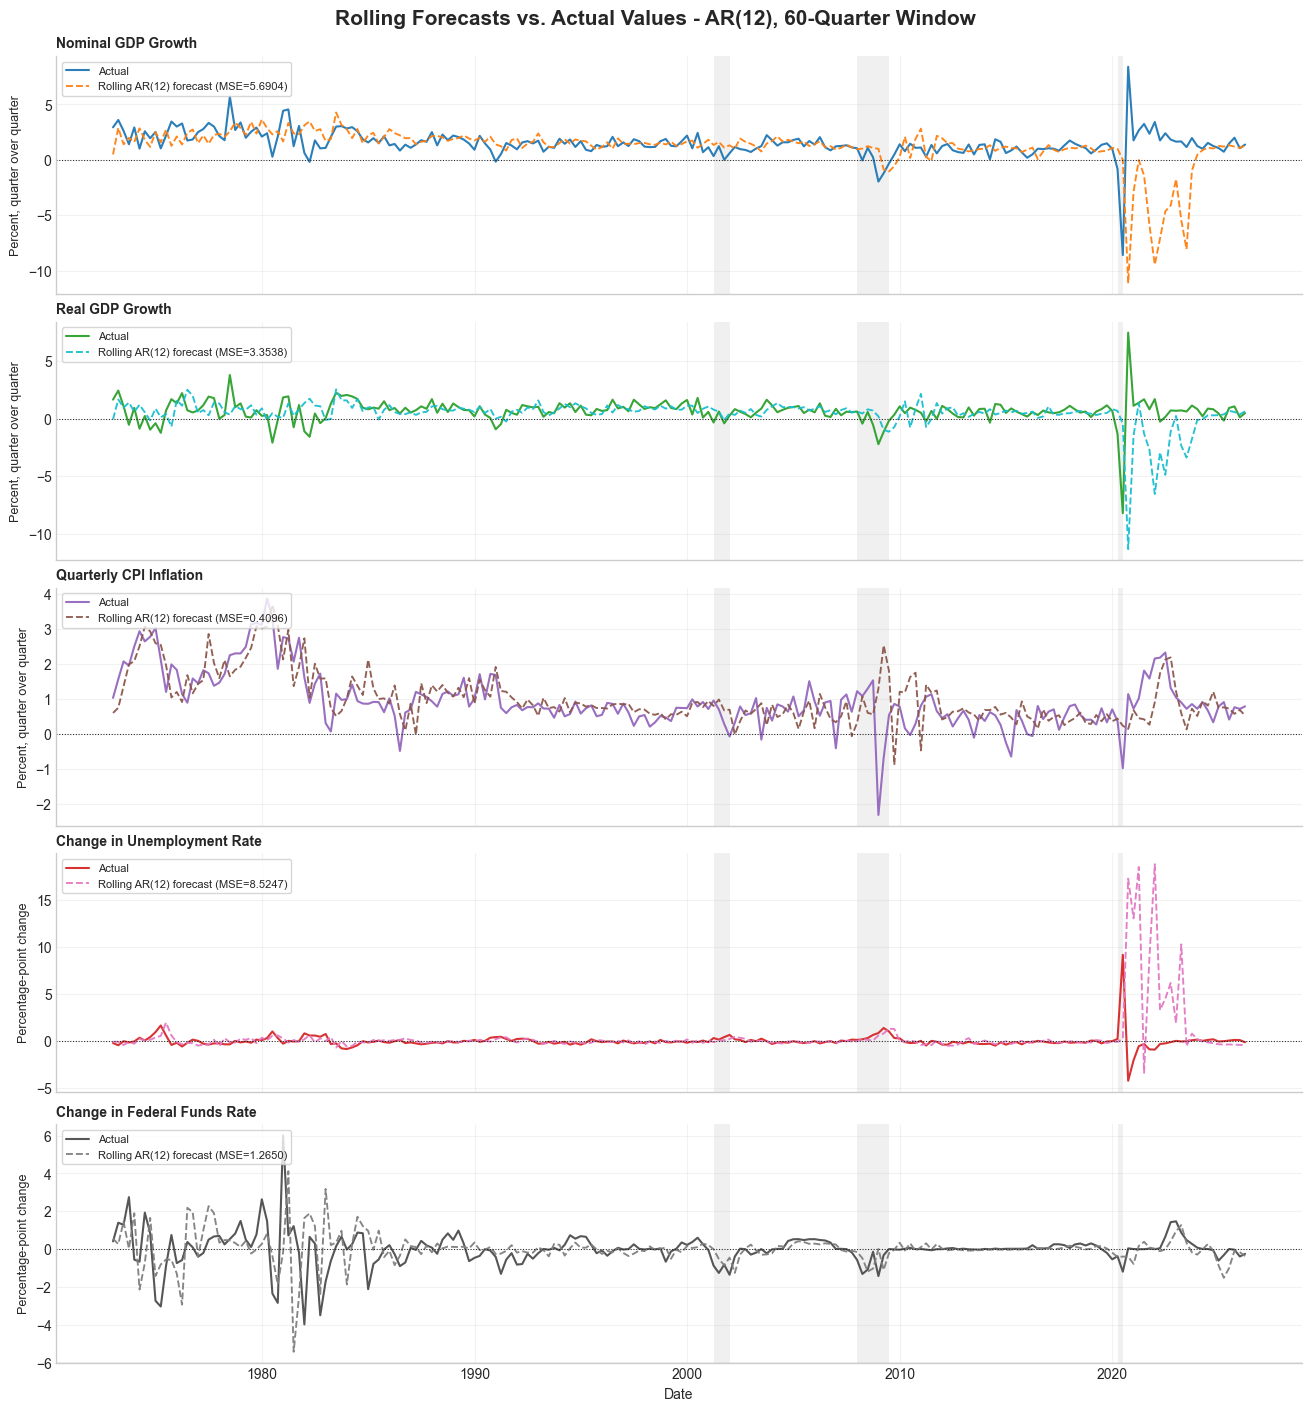

In [34]:
# Section 6 - Plot rolling forecast vs actuals
colors_act = [plot_colors[v] for v in transformed_variables]
colors_fit = ["#ff7f0e", "#17becf", "#8c564b", "#e377c2", "#7f7f7f"]

fig, axes = plt.subplots(len(transformed_variables), 1, figsize=(13, 14), sharex=True, constrained_layout=True)
for ax, var, ca, cf in zip(axes, transformed_variables, colors_act, colors_fit):
    r = rolling_results_60[var]
    add_recession_bands(ax)
    ax.plot(r['dates'], r['actuals'], color=ca, lw=1.5, label='Actual', alpha=0.95)
    ax.plot(r['dates'], r['forecasts'], color=cf, lw=1.35, ls='--',
            label=f'Rolling AR({N_LAGS}) forecast (MSE={r["mse"]:.4f})', alpha=0.95)
    ax.axhline(0, color='#222222', lw=0.75, ls=':')
    ax.set_title(f"{friendly_names[var]}", loc='left', fontsize=10, fontweight='bold')
    ax.set_ylabel(series_units[var], fontsize=9)
    ax.legend(fontsize=8, loc='upper left', frameon=True)
    format_time_axis(ax, year_interval=10)

axes[-1].set_xlabel('Date')
fig.suptitle(f'Rolling Forecasts vs. Actual Values - AR({N_LAGS}), {WINDOW_SIZE}-Quarter Window', fontsize=15, fontweight='bold')
plt.show()

### Discussion

**What rolling window size did we choose?**  
We used 60 quarters (15 years).

**Why is this window size reasonable?**  
Sixty quarters gives 48 usable regression rows after 12 lags, which is enough to estimate the 13 AR(12) parameters while still allowing the window to adapt to gradual structural change.

**What are the trade-offs between a short and a long window?**  
A shorter window reacts faster to structural breaks but produces noisier estimates; a longer window yields more stable estimates but may incorporate outdated data from a different macroeconomic regime.

**What is the MSE for each variable?**  
See the printed table above. Real GDP growth and unemployment changes tend to have larger MSEs because they are more affected by sudden recessionary shocks, while inflation and interest-rate changes are more persistent but still difficult around policy turning points.

---
## Section 7 - Experiment with Lags and Window Sizes

We repeat the rolling window exercise using three lag lengths (4, 8, and 12 quarters) and three window sizes (40, 60, and 80 quarters), giving 9 specifications in total. MSE is reported for each combination.

In [35]:
# Section 7 — Grid of lag lengths and window sizes
LAG_CHOICES    = [4, 8, 12]
WINDOW_CHOICES = [40, 60, 80]

mse_grid = {}
for w in WINDOW_CHOICES:
    for p in LAG_CHOICES:
        key = (w, p)
        mse_grid[key] = {}
        for var in transformed_variables:
            d, y_act, y_fc = rolling_forecast(df_stationary[var], w, p)
            mse_grid[key][var] = np.mean((y_act - y_fc) ** 2)

rows = []
for (w, p), var_mses in mse_grid.items():
    for var, mse in var_mses.items():
        rows.append({'Window (q)': w, 'Lags (p)': p, 'Variable': var, 'MSE': mse})

mse_df = pd.DataFrame(rows)
pivot  = mse_df.pivot_table(index=['Window (q)', 'Lags (p)'], columns='Variable',
                             values='MSE').round(6)
print('Rolling Window MSE by Specification')
print('=' * 90)
print(pivot.to_string())


Rolling Window MSE by Specification
Variable             CPI_qoq_inflation  FEDFUNDS_diff  GDPC1_log_diff  GDP_log_diff  UNRATE_diff
Window (q) Lags (p)                                                                             
40         4                  0.273628       1.039892        4.059637      4.344053    17.723221
           8                  0.370392       1.336352        6.452897      7.682131    46.332150
           12                 0.550323       3.063844       13.913751     18.374445    75.670344
60         4                  0.283777       1.032001        2.329197      3.050133     4.419599
           8                  0.360215       1.146810        2.762487      4.010397     6.758620
           12                 0.409631       1.265005        3.353807      5.690399     8.524703
80         4                  0.275268       0.906898        2.223657      3.016051     3.833133
           8                  0.327886       0.998097        2.572522      3.749604     5.9

### Discussion

**Which specification performs best according to MSE?**  
The best specification varies by variable, which is common in macroeconomic forecasting. The MSE grid should therefore be read variable-by-variable rather than as one universal winner.

**Does using more lags improve the forecast?**  
Not consistently. More lags can capture longer persistence and delayed adjustment, but they also add parameters and estimation noise. The AR(12) specification is required for the main assignment model, while the shorter AR(4) and AR(8) specifications show whether a more parsimonious model forecasts better.

**Does changing the window size improve the forecast?**  
Sometimes. A 40-quarter window can adapt more quickly to structural breaks, while an 80-quarter window gives more stable estimates. The 60-quarter window is a reasonable compromise.

**Is the best-performing model also the most economically convincing model?**  
Not necessarily. A specification can win by a small MSE margin without being the most interpretable or robust. The AR(12) model is economically defensible because it uses three years of quarterly history and matches the assignment requirement, even if a shorter lag length occasionally performs better for a specific variable.

---
## Section 8 — Compare with a No-Change Forecast

The no-change forecast predicts that next period equals this period:

$$\hat{y}_{t+1} = y_t$$

We compute rolling no-change MSE over the same evaluation window as Section 6 and compare it with the AR(12) MSE.


In [36]:
# Section 8 — No-change (random walk) benchmark
def rolling_no_change(series, window, n_lags):
    arr = series.dropna().values.astype(float)
    idx = series.dropna().index
    T   = len(arr)
    start = window + n_lags
    dates, actuals, forecasts = [], [], []
    for t in range(start, T):
        dates.append(idx[t])
        actuals.append(arr[t])
        forecasts.append(arr[t - 1])   # no-change: y_hat_{t+1} = y_t
    return np.array(dates), np.array(actuals), np.array(forecasts)

print(f'MSE Comparison: AR(12) Rolling (window={WINDOW_SIZE}q) vs No-Change Benchmark')
print('=' * 72)
print(f'  {"Variable":<24s}  {"AR(12) MSE":>12s}  {"No-Change MSE":>14s}  {"AR beats?":>10s}')
print('-' * 72)

benchmark_results = {}
for var in transformed_variables:
    d, y_act, y_nc = rolling_no_change(df_stationary[var], WINDOW_SIZE, N_LAGS)
    nc_mse = np.mean((y_act - y_nc) ** 2)
    ar_mse = rolling_results_60[var]['mse']
    beats  = 'Yes' if ar_mse < nc_mse else 'No'
    benchmark_results[var] = {'nc_mse': nc_mse, 'ar_mse': ar_mse}
    print(f'  {var:<24s}  {ar_mse:>12.6f}  {nc_mse:>14.6f}  {beats:>10s}')


MSE Comparison: AR(12) Rolling (window=60q) vs No-Change Benchmark
  Variable                    AR(12) MSE   No-Change MSE   AR beats?
------------------------------------------------------------------------
  GDP_log_diff                  5.690399        2.609412          No
  GDPC1_log_diff                3.353807        2.289444          No
  CPI_qoq_inflation             0.409631        0.328387          No
  UNRATE_diff                   8.524703        1.312052          No
  FEDFUNDS_diff                 1.265005        1.244130          No


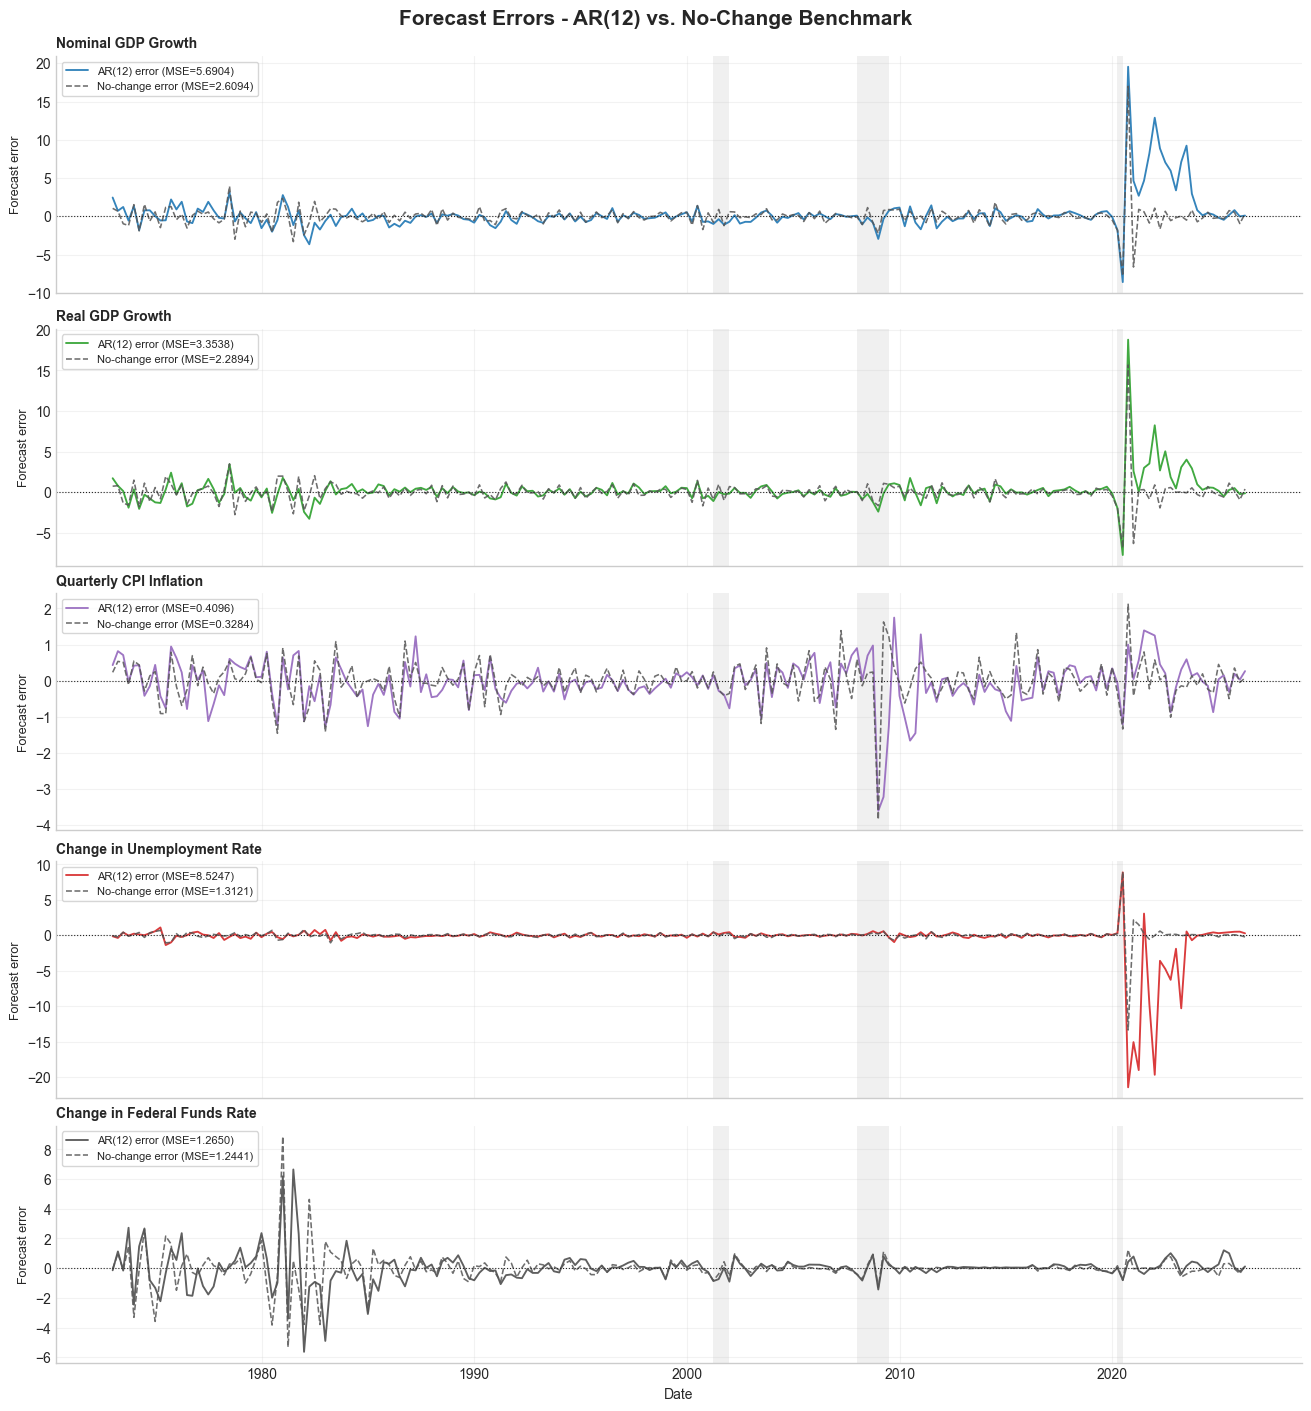

In [37]:
# Section 8 - Plot forecast errors: AR(12) vs no-change
fig, axes = plt.subplots(len(transformed_variables), 1, figsize=(13, 14), sharex=True, constrained_layout=True)
for ax, var, ca in zip(axes, transformed_variables, colors_act):
    r = rolling_results_60[var]
    d2, ya2, nc2 = rolling_no_change(df_stationary[var], WINDOW_SIZE, N_LAGS)
    nc_err = ya2 - nc2
    add_recession_bands(ax)
    ax.plot(r['dates'], r['errors'], color=ca, lw=1.35, alpha=0.9,
            label=f'AR({N_LAGS}) error (MSE={r["mse"]:.4f})')
    ax.plot(d2, nc_err, color='#555555', lw=1.15, ls='--', alpha=0.85,
            label=f'No-change error (MSE={benchmark_results[var]["nc_mse"]:.4f})')
    ax.axhline(0, color='#222222', lw=0.8, ls=':')
    ax.set_title(f"{friendly_names[var]}", loc='left', fontsize=10, fontweight='bold')
    ax.set_ylabel('Forecast error', fontsize=9)
    ax.legend(fontsize=8, loc='upper left', frameon=True)
    format_time_axis(ax, year_interval=10)

axes[-1].set_xlabel('Date')
fig.suptitle(f'Forecast Errors - AR({N_LAGS}) vs. No-Change Benchmark', fontsize=15, fontweight='bold')
plt.show()

### Discussion

**Why is the no-change forecast a useful benchmark?**  
The no-change forecast uses zero estimated parameters and is always trivially available. Any more-sophisticated model must show that its added complexity actually reduces forecast error relative to this baseline.

**Does our model beat the no-change forecast?**  
The printed comparison table answers this variable by variable. In general, the AR(12) model may help for persistent variables, but it does not automatically dominate the no-change benchmark because the additional lags can add estimation noise.

**If the model does not beat the benchmark, what does that imply?**  
It implies that the extra lagged information used by the AR model does not improve one-step-ahead forecasts enough to justify the added complexity for that variable and sample.

**Why might a very simple forecast perform well for macroeconomic data?**  
Macroeconomic series are dominated by large, unpredictable shocks - recessions, policy shifts, pandemics - that overwhelm any systematic pattern the AR model captures. The no-change forecast is also robust to misspecification because it makes no functional-form assumptions.

---
## Section 9 - Evaluate the Model

### MSE Summary Table

The table below reports the baseline AR(12), 60-quarter rolling-window MSE and the matching no-change benchmark MSE.

In [38]:
# Section 9 - MSE summary table
mse_summary = pd.DataFrame([
    {
        "Variable": var,
        "AR(12) MSE (window=60q)": benchmark_results[var]["ar_mse"],
        "No-Change MSE": benchmark_results[var]["nc_mse"],
        "AR beats benchmark?": "Yes" if benchmark_results[var]["ar_mse"] < benchmark_results[var]["nc_mse"] else "No",
    }
    for var in transformed_variables
])
display(mse_summary.round(6))

,Variable,AR(12) MSE (window=60q),No-Change MSE,AR beats benchmark?
0,GDP_log_diff,5.690399,2.609412,No
1,GDPC1_log_diff,3.353807,2.289444,No
2,CPI_qoq_inflation,0.409631,0.328387,No
3,UNRATE_diff,8.524703,1.312052,No
4,FEDFUNDS_diff,1.265005,1.244130,No


### Discussion

**Is the model useful? Why or why not?**  
The AR(12) model is useful as a transparent, replicable baseline that captures persistence over three years of quarterly observations. It is not guaranteed to beat the no-change benchmark, but it provides a systematic way to test whether lagged values contain useful forecasting information.

**Does the model work better for some variables than others?**  
Yes. The model tends to work better for variables with stronger serial correlation and smoother adjustment. It performs less well for variables whose changes are dominated by sudden shocks, such as unemployment during recessions or GDP growth during COVID-19.

**Are there periods where the model performs especially poorly?**  
The COVID-19 shock in 2020 Q2 produces extreme forecast errors across all variables: GDP collapsed, unemployment spiked, and the Fed cut rates sharply; none of which the model could anticipate from recent history. The 2008-09 GFC and the 2021-22 inflation surge also generate larger-than-usual errors.

**Could structural breaks, recessions, COVID, inflation episodes, or policy changes affect results?**  
Yes. Structural breaks change the persistence and variance of the series, so coefficients estimated on one regime may forecast poorly in another. COVID, high-inflation episodes, and zero-lower-bound monetary policy are all examples where a fixed univariate AR model is likely to struggle.

**What would we try next to improve the model?**  
1. **VAR (Vector Autoregression):** Allow cross-variable predictive relationships, e.g., use lagged unemployment to help forecast GDP growth.  
2. **Recursive estimation:** Grow the window with each new observation rather than rolling it; more stable for slowly-varying dynamics.  
3. **Model selection:** Use AIC/BIC to choose lag length each period rather than fixing p=12.  
4. **LASSO/Ridge:** Shrink lag coefficients for lags with little predictive power, reducing estimation noise.  
5. **Real-time data:** Use vintage data to simulate the information set actually available at each forecast origin, avoiding look-ahead bias.

---
## Appendix - AI Coding Prompts Used

**Section 1 (FRED data):**
> *"Write Python code to download GDP, GDPC1, CPIAUCSL, UNRATE, and FEDFUNDS from FRED using the public CSV endpoint, convert monthly series to quarterly averages, align all variables into one quarterly DataFrame, and print a metadata table with FRED code, frequency, sample period, and what each variable measures."*

**Section 2 (Stationarity and transformations):**
> *"For the FRED macro dataset, write concise explanations of stationarity, why trending macro series are problematic, and which transformations are appropriate for GDP, real GDP, CPI, unemployment, and the federal funds rate. Use ADF tests to compare original and transformed series."*

**Section 3 (Discussion):**
> *"I have plotted raw and transformed macroeconomic series for GDP, GDPC1, CPIAUCSL, UNRATE, and FEDFUNDS. Write discussion answers for: (1) what patterns appear in the raw data, (2) what trends, spikes, or recessions are visible, (3) how the transformed series differs from the raw series, and (4) whether the transformation changes the economic interpretation."*

**Section 4 (Matrix regression):**
> *"Write a pure numpy function `build_XY(series, n_lags)` that constructs the OLS dependent variable y and regressor matrix X from a pandas Series. Estimate AR(12) models for GDP_log_diff, GDPC1_log_diff, CPI_qoq_inflation, UNRATE_diff, and FEDFUNDS_diff using beta_hat = (X'X)^(-1)X'y. Print y shape, X shape, beta_hat shape, and all coefficients. Verify against statsmodels."*

**Section 5 (Forecast):**
> *"Given the estimated AR(12) beta vectors from Section 4, write a `forecast_next(series, beta, n_lags)` function that constructs x_{T+1} = [1, y_T, y_{T-1}, ..., y_{T-11}] and returns y_hat_{T+1} = x_{T+1} @ beta. Print a comparison table of model forecasts versus current official forecasts from the Fed SEP and Survey of Professional Forecasters, noting unit differences. Then plot the last 6 years of each series with the forecast point connected by a dashed line."*

**Section 6 (Rolling window forecast):**
> *"Write a Python function `rolling_forecast(series, window, n_lags)` that performs a rolling one-step-ahead AR(n_lags) forecast using a fixed window. For each t from `window+n_lags` to end of sample, estimate AR on the preceding `window` observations using pure NumPy OLS, forecast the next value, and move the window forward one quarter. Return arrays of dates, actuals, and forecasts. Compute MSE. Apply with window=60 and n_lags=12 to all five quarterly transformed variables and plot actuals vs forecasts."*

**Section 7 (Lag and window grid):**
> *"Repeat rolling forecasts for all combinations of lags in [4, 8, 12] and windows in [40, 60, 80]. Store MSE results keyed by (window, lags). Build a pivot_table to display MSE for all 9 specifications and 5 variables in one formatted table."*

**Section 8 (No-change benchmark):**
> *"Write `rolling_no_change(series, window, n_lags)` producing a no-change forecast y_hat_{t+1} = y_t over the same evaluation window as the rolling AR(12) forecast. Print a comparison table: AR(12) MSE vs no-change MSE, with a column indicating which is lower. Plot forecast errors for both models on the same axes."*

**Section 9 (Model evaluation):**
> *"Create a final MSE summary table and write a short evaluation covering: (1) whether the model is useful and for which variables, (2) periods of especially large errors such as COVID and the GFC, (3) how structural breaks and inflation episodes affect results, and (4) at least four concrete improvements that could be tried next."*